# Imports

In [1]:
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split

import numpy as np
import random
import time

import torchvision
from torchvision import transforms
import torchvision.transforms.functional as TF
from torchvision.datasets import OxfordIIITPet

import matplotlib.pyplot as plt

# Universal Variables

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed(RANDOM_SEED)

#Loading Dataset

In [4]:
class oxfordPetDataset(Dataset):
    def __init__(self,root, split="trainval", imgSize=256, augment=False):

        self.dataset = OxfordIIITPet(root, split=split, target_types="segmentation", download=True)
        self.imgSize = imgSize
        self.augment = augment

        self.imgResize = transforms.Resize((imgSize,imgSize), antialias = True)
        self.imgToTensor = transforms.ToTensor()

        self.maskResize = transforms.Resize((imgSize,imgSize), antialias = True, interpolation = transforms.InterpolationMode.NEAREST)

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self,idx):
        # Getting image and mask from dataset
        img, mask = self.dataset[idx]

        # Resizing the image and mask as per user inputted size
        img = self.imgResize(img)
        mask = self.maskResize(mask)

        # Simple Augmentation (where 25% to flip horizontally or Vertically)
        if self.augment and random.random() < 0.25:
          img = TF.hflip(img)
          mask = TF.hflip(mask)
        elif self.augment and random.random() >= 0.75:
          img = TF.vflip(img)
          mask = TF.vflip(mask)

        # Converting image to Tensor
        imgTensor = self.imgToTensor(img)

        # Converting mask from numpy to Tensor
        maskNumpy = np.array(mask, dtype=np.int64)
        maskBinary = ((maskNumpy == 1) | (maskNumpy == 3)).astype(np.int64)
        maskTensor = torch.from_numpy(maskBinary)

        return imgTensor, maskTensor

In [5]:
dataRoot = "/content/oxford_pets"
opDs = oxfordPetDataset(root=dataRoot, split="trainval", imgSize=256, augment=True)
print("Dataset size:", len(opDs))

Dataset size: 3680


# U-Net Implementations

## Common Code

In [6]:
def dConvLayers(inCh,outCh):
    convOperation = nn.Sequential(
        nn.Conv2d(inCh,inCh,kernel_size=3,padding=1),
        nn.BatchNorm2d(inCh),
        nn.ReLU(inplace=True),
        nn.Conv2d(inCh,outCh,kernel_size=3,padding=1),
        nn.BatchNorm2d(outCh),
        nn.ReLU(inplace=True),
        nn.Conv2d(outCh,outCh,kernel_size=3,padding=1),
        nn.BatchNorm2d(outCh),
        nn.ReLU(inplace=True)
    )

    return convOperation

## Simple U-net

In [7]:
class simpleUNet(nn.Module):
    def __init__(self,numClass):
        super(simpleUNet, self).__init__()

        self.maxPool2d = nn.MaxPool2d(kernel_size=2,stride=2)

        self.downConv1 = dConvLayers(3,64)
        self.downConv2 = dConvLayers(64,128)
        self.downConv3 = dConvLayers(128,256)
        self.downConv4 = dConvLayers(256,512)
        self.downConv5 = dConvLayers(512,1024)

        self.upTrans1 = nn.ConvTranspose2d(in_channels=1024, out_channels=512, kernel_size=2,stride=2)
        self.upTrans2 = nn.ConvTranspose2d(in_channels=512, out_channels=256, kernel_size=2,stride=2)
        self.upTrans3 = nn.ConvTranspose2d(in_channels=256, out_channels=128, kernel_size=2,stride=2)
        self.upTrans4 = nn.ConvTranspose2d(in_channels=128, out_channels=64, kernel_size=2,stride=2)

        self.upConv1 = dConvLayers(1024,512)
        self.upConv2 = dConvLayers(512,256)
        self.upConv3 = dConvLayers(256,128)
        self.upConv4 = dConvLayers(128,64)

        self.outLayer = nn.Conv2d(in_channels=64,out_channels=numClass,kernel_size=1)

    def forward(self,x):
        saveD1 = self.downConv1(x)
        x = self.maxPool2d(saveD1)
        saveD2 = self.downConv2(x)
        x = self.maxPool2d(saveD2)
        saveD3 = self.downConv3(x)
        x = self.maxPool2d(saveD3)
        saveD4 = self.downConv4(x)
        x = self.maxPool2d(saveD4)
        saveD5 = self.downConv5(x)

        saveU1 = self.upTrans1(saveD5)
        x = self.upConv1(torch.cat([saveD4,saveU1],1))

        saveU2 = self.upTrans2(x)
        x = self.upConv2(torch.cat([saveD3,saveU2],1))

        saveU3 = self.upTrans3(x)
        x = self.upConv3(torch.cat([saveD2,saveU3],1))

        saveU4 = self.upTrans4(x)
        x = self.upConv4(torch.cat([saveD1,saveU4],1))

        return self.outLayer(x)


## Devovled U-net

In [8]:
class devolvedUNet(nn.Module):
    def __init__(self,numClass):
        super(devolvedUNet, self).__init__()

        self.maxPool2d = nn.MaxPool2d(kernel_size=2,stride=2)

        self.downConv1 = dConvLayers(3,64)
        self.downConv2 = dConvLayers(64,128)
        self.downConv3 = dConvLayers(128,256)
        self.downConv4 = dConvLayers(256,512)
        self.downConv5 = dConvLayers(512,1024)

        self.upTrans1 = nn.ConvTranspose2d(in_channels=1024, out_channels=512, kernel_size=2,stride=2)
        self.upTrans2 = nn.ConvTranspose2d(in_channels=512, out_channels=256, kernel_size=2,stride=2)
        self.upTrans3 = nn.ConvTranspose2d(in_channels=256, out_channels=128, kernel_size=2,stride=2)
        self.upTrans4 = nn.ConvTranspose2d(in_channels=128, out_channels=64, kernel_size=2,stride=2)

        self.upConv1 = dConvLayers(1024,512)
        self.upConv2 = dConvLayers(512,256)
        self.upConv3 = dConvLayers(256,128)
        self.upConv4 = dConvLayers(128,64)

        self.outLayer = nn.Conv2d(in_channels=64,out_channels=numClass,kernel_size=1)

    def forward(self,x):
        x = self.downConv1(x)
        x = self.maxPool2d(x)
        x = self.downConv2(x)
        x = self.maxPool2d(x)
        x = self.downConv3(x)
        x = self.maxPool2d(x)
        x = self.downConv4(x)
        x = self.maxPool2d(x)
        x = self.downConv5(x)

        x = self.upTrans1(x)
        x = self.upTrans2(x)
        x = self.upTrans3(x)
        x = self.upTrans4(x)

        return self.outLayer(x)


## Special U-Net

In [9]:
class specialUNet(nn.Module):
    def __init__(self,numClass):
        super(specialUNet, self).__init__()

        self.maxPool2d = nn.MaxPool2d(kernel_size=2,stride=2)

        self.downConv1 = dConvLayers(3,64)
        self.downConv2 = dConvLayers(64,128)
        self.downConv3 = dConvLayers(128,256)
        self.downConv4 = dConvLayers(256,512)
        self.downConv5 = dConvLayers(512,1024)

        self.downSConv1 = dConvLayers(3,64)
        self.downSConv2 = dConvLayers(64,128)
        self.downSConv3 = dConvLayers(128,256)
        self.downSConv4 = dConvLayers(256,512)

        self.upTrans1 = nn.ConvTranspose2d(in_channels=1024, out_channels=512, kernel_size=2,stride=2)
        self.upTrans2 = nn.ConvTranspose2d(in_channels=512, out_channels=256, kernel_size=2,stride=2)
        self.upTrans3 = nn.ConvTranspose2d(in_channels=256, out_channels=128, kernel_size=2,stride=2)
        self.upTrans4 = nn.ConvTranspose2d(in_channels=128, out_channels=64, kernel_size=2,stride=2)

        self.upConv1 = dConvLayers(1024,512)
        self.upConv2 = dConvLayers(512,256)
        self.upConv3 = dConvLayers(256,128)
        self.upConv4 = dConvLayers(128,64)

        self.outLayer = nn.Conv2d(in_channels=64,out_channels=numClass,kernel_size=1)

    def forward(self,x):
        saveD0 = self.downSConv1(x)

        x = self.downConv1(x)
        x = self.maxPool2d(x)
        saveD1 = self.downSConv2(x)

        x = self.downConv2(x)
        x = self.maxPool2d(x)
        saveD2 = self.downSConv3(x)

        x = self.downConv3(x)
        x = self.maxPool2d(x)
        saveD3 = self.downSConv4(x)

        x = self.downConv4(x)
        x = self.maxPool2d(x)

        x = self.downConv5(x)

        saveU1 = self.upTrans1(x)
        x = self.upConv1(torch.cat([saveD3,saveU1],1))

        saveU2 = self.upTrans2(x)
        x = self.upConv2(torch.cat([saveD2,saveU2],1))

        saveU3 = self.upTrans3(x)
        x = self.upConv3(torch.cat([saveD1,saveU3],1))

        saveU4 = self.upTrans4(x)
        x = self.upConv4(torch.cat([saveD0,saveU4],1))

        return self.outLayer(x)


# Creating the Models

In [10]:
devoModel = devolvedUNet(numClass=2)
specModel = specialUNet(numClass=2)
normalModel = simpleUNet(numClass=2)

# Loading the Weights

Here we will be loading the experiment which has run for 25 epochs in the baseline experimentation.

The basic logic is load weights into model and then transfer that to the device (cpu or gpu)

In [11]:
devoModelPath = "/content/drive/MyDrive/Image_Processing/Runs Model and Weights Folder/devolved-u-net-25-Epoch.pth"
normalModelPath = "/content/drive/MyDrive/Image_Processing/Runs Model and Weights Folder/normal-u-net-25-Epoch.pth"
specModelPath = "/content/drive/MyDrive/Image_Processing/Runs Model and Weights Folder/special-u-net-25-Epoch.pth"

In [12]:
devoModel.load_state_dict(torch.load(devoModelPath,weights_only=True))
devoModel.to(device)
devoModel.eval()

devolvedUNet(
  (maxPool2d): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (downConv1): Sequential(
    (0): Conv2d(3, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
  )
  (downConv2): Sequential(
    (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)

In [13]:
normalModel.load_state_dict(torch.load(normalModelPath,weights_only=True))
normalModel.to(device)
normalModel.eval()

simpleUNet(
  (maxPool2d): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (downConv1): Sequential(
    (0): Conv2d(3, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
  )
  (downConv2): Sequential(
    (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))


In [14]:
specModel.load_state_dict(torch.load(specModelPath,weights_only=True))
specModel.to(device)
specModel.eval()

specialUNet(
  (maxPool2d): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (downConv1): Sequential(
    (0): Conv2d(3, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
  )
  (downConv2): Sequential(
    (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))

# Showing Sample Predictions

In [15]:
@torch.no_grad()
def predict(imgTensor, model):
  model.eval()
  x = imgTensor.unsqueeze(0).to(device)
  logits = model(x)[0].cpu()
  return logits.argmax(dim=0)

def showPreds(imgTensor, maskTensor, predTensor,title=""):
  img = imgTensor.permute(1,2,0).cpu().numpy()
  mask = maskTensor.cpu().numpy()
  pred = predTensor.cpu().numpy()

  plt.figure(figsize = (12,4))

  plt.subplot(1,4,1)
  plt.imshow(img)
  plt.axis("off")
  plt.title("Image")

  plt.subplot(1,4,2)
  plt.imshow(mask)
  plt.axis("off")
  plt.title("Mask")

  plt.subplot(1,4,3)
  plt.imshow(pred)
  plt.axis("off")
  plt.title("Predicted Mask")

  plt.subplot(1,4,4)
  plt.imshow(img)
  plt.imshow(pred,alpha=0.4)
  plt.axis("off")
  plt.title("Overlay of Predicted")

  plt.suptitle(title)
  plt.show()

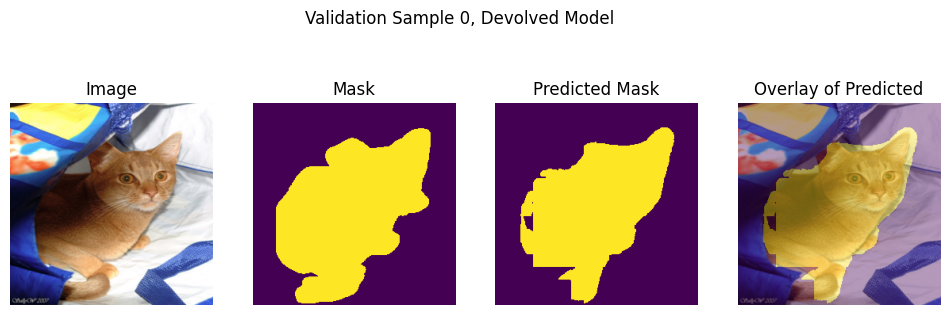

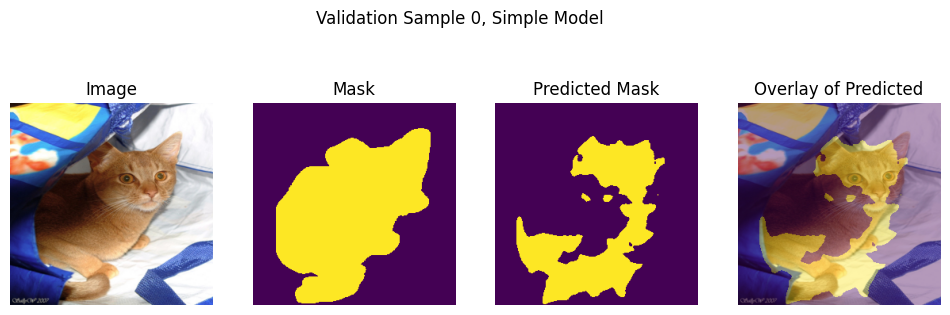

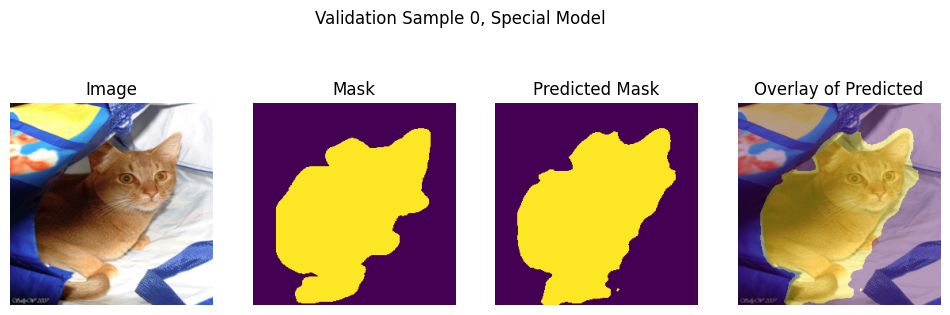

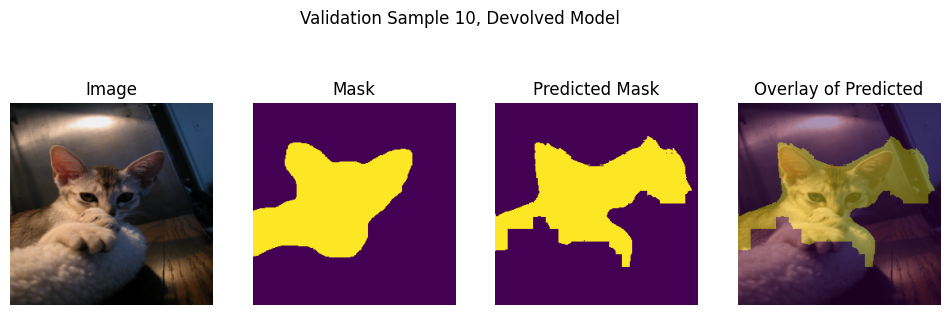

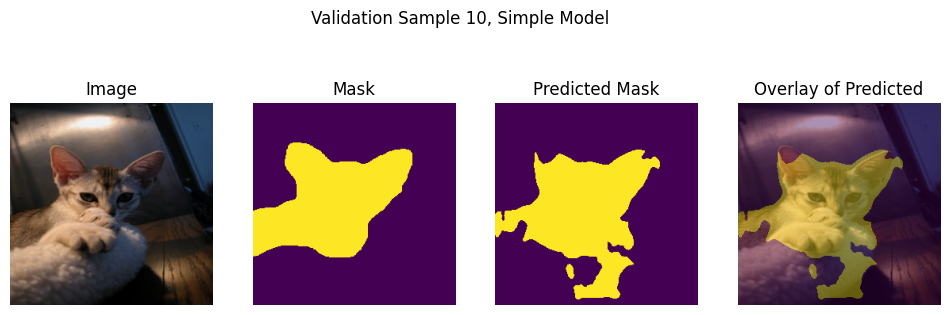

...

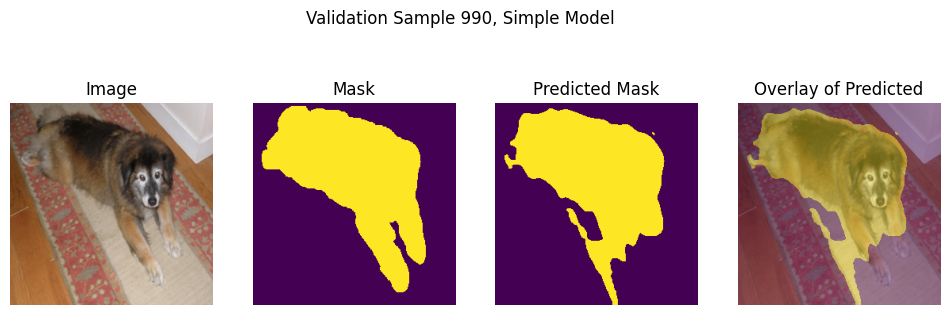

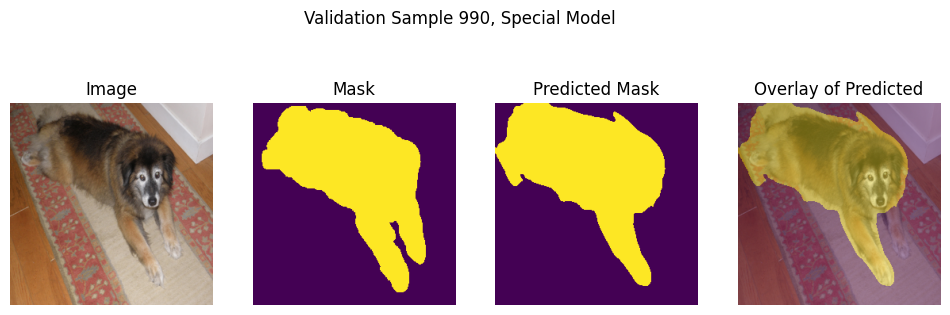

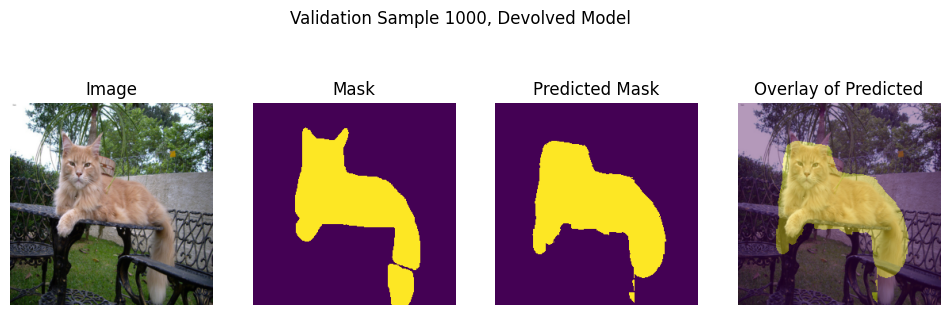

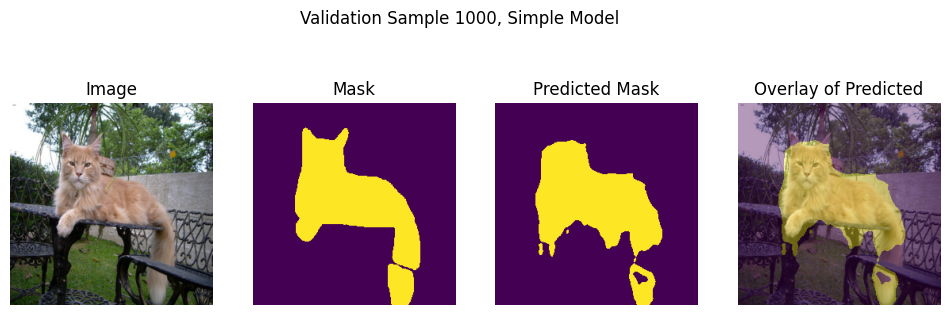

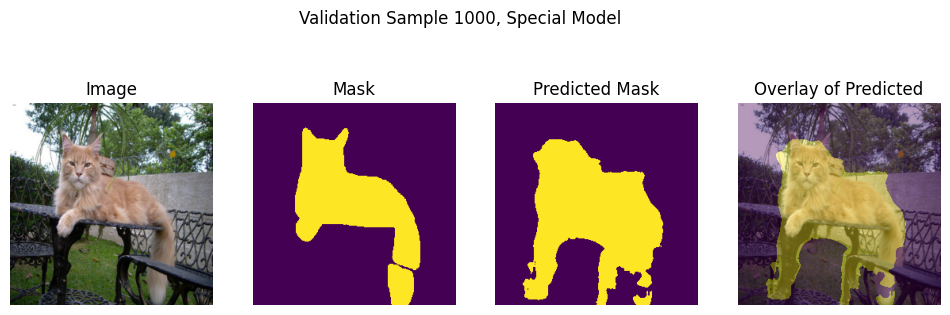

In [16]:
for i in range(0,1001,10):
  imgTensor, maskTensor = opDs[i]
  predTensor = predict(imgTensor,devoModel)
  showPreds(imgTensor, maskTensor, predTensor, title=f"Validation Sample {i}, Devolved Model")
  predTensor = predict(imgTensor,normalModel)
  showPreds(imgTensor, maskTensor, predTensor, title=f"Validation Sample {i}, Simple Model")
  predTensor = predict(imgTensor,specModel)
  showPreds(imgTensor, maskTensor, predTensor, title=f"Validation Sample {i}, Special Model")